# PTB-XL: local and Colab ECG forecasting

Observe 7 seconds and forecast the next 3 seconds of each 10-second ECG.
The notebook calls the project source and uses the same models in both environments.

- **Local:** open this notebook in Jupyter or VS Code, select the project's Python
  environment, and run all cells. Project and data paths are set in the first cell.
- **Colab:** set your Drive project folder or upload the source ZIP. Use Drive
  data or choose the official PhysioNet download.

Start with **pilot**. Change the patient counts in the first cell to use a different
cohort, and use a new `STUDY_ID` when you do. For the full workflow set `RUN_MODE`
to `full` and `EPOCHS` to `120`. Full training requires CUDA unless explicitly
enabled on CPU. Set `FINAL_TEST=True` only to evaluate the frozen models on fold 10.
Use `RESUME=True` to continue an interrupted run with the same settings.

In [21]:
import os
from pathlib import Path
os.environ.setdefault('CUBLAS_WORKSPACE_CONFIG', ':4096:8')

# Environment: auto selects Colab there and local Jupyter/VS Code elsewhere.
EXECUTION_ENV = 'auto'              # auto | local | colab
INSTALL_DEPENDENCIES = None         # None: install in Colab only; True: install here too
TRAINING_DEVICE = 'auto'            # auto | cpu | cu

# Local paths: relative paths are resolved from the project root.
LOCAL_PROJECT_DIR = None            # Auto-find from the starting directory; or use an absolute path
LOCAL_DATA_ROOT = 'PTB-XL'          # E.g. r'D:\Datasets\PTB-XL' if stored elsewhere
LOCAL_CACHE_DIR = 'data/study_v3'
LOCAL_RESULTS_DIR = 'results'

# Experiment and patient counts.
PILOT_TRAIN_PATIENTS = 300
PILOT_VAL_PATIENTS = 75
MEDIUM_TRAIN_PATIENTS = 1500
MEDIUM_VAL_PATIENTS = None          # None uses all of official fold 9

RUN_MODE = 'medium'                   # pilot | medium | full
EPOCHS = 60                         # medium: 60; FULL preset: 120
BATCH_SIZE = 64
STUDY_ID = 'primary_7s3s_v5'
RESUME = False
FINAL_TEST = False
ALLOW_FULL_CPU = False
ALLOW_PRIOR_HISTORY = False          # requires a passing chronology audit
TUNE_HIDDEN_128 = False              # secondary ablation
# Colab project paths. Set DRIVE_PROJECT if loading your source folder from Drive.
PROJECT_SOURCE = 'drive'             # drive | upload_zip (Colab only)
DRIVE_PROJECT = ''
PROJECT_DIR = '/content/ptbxl_assignment'  # Extraction destination for a Colab upload
DATA_SOURCE = 'auto'                 # auto | local | drive | physionet
DATA_ROOT = '/content/drive/MyDrive/PTB-XL'
DRIVE_OUTPUT = '/content/drive/MyDrive/ptbxl_research'
SINGLE_RUN = False                   # optional manual experiment instead of the study stages
ARCHITECTURE = 'lstm'
FILTERING = 'P0'                     # P0 | P1; used by SINGLE_RUN
FEATURE_SET = 'F0'                   # F0 | F1 | F2 | expanded; used by SINGLE_RUN
VALIDATION_FIXTURE = os.environ.get('PTBXL_NOTEBOOK_FIXTURE')
FIXTURE_PROJECT = os.environ.get('PTBXL_NOTEBOOK_PROJECT')
if EXECUTION_ENV not in ('auto', 'local', 'colab'):
    raise ValueError('EXECUTION_ENV must be auto, local, or colab.')
if TRAINING_DEVICE not in ('auto', 'cpu', 'cuda'):
    raise ValueError('TRAINING_DEVICE must be auto, cpu, or cuda.')
assert RUN_MODE in ('pilot', 'medium', 'full')
if RUN_MODE == 'full' and EPOCHS != 120:
    raise ValueError('The FULL preset requires EPOCHS=120. Use medium for the 60-epoch study.')

## 1. Locate the project

Locally, open this notebook from the extracted project or set `LOCAL_PROJECT_DIR`
to the directory with `src/`, `configs/`, and `requirements.txt`. Google Drive
is only mounted in Colab. There, set `DRIVE_PROJECT` or choose an uploaded source
ZIP. ZIP extraction rejects paths outside the project and symbolic links.

In [22]:
import sys
import zipfile
from importlib.util import find_spec

required_project_files = ('src/pipeline.py', 'configs/config.yaml', 'requirements.txt')
runtime = EXECUTION_ENV
if VALIDATION_FIXTURE:
    runtime = 'local'
elif runtime == 'auto':
    try:
        running_in_colab = find_spec('google.colab') is not None
    except ModuleNotFoundError:
        running_in_colab = False
    runtime = 'colab' if running_in_colab else 'local'

if VALIDATION_FIXTURE:
    if not FIXTURE_PROJECT:
        raise ValueError('Software validation requires PTBXL_NOTEBOOK_PROJECT.')
    project = Path(FIXTURE_PROJECT).resolve()
elif runtime == 'local':
    if LOCAL_PROJECT_DIR:
        project = Path(LOCAL_PROJECT_DIR).expanduser().resolve()
    else:
        start = Path.cwd().resolve()
        project = next(
            (p for p in (start, *start.parents)
             if all((p / name).is_file() for name in required_project_files)),
            None,
        )
        if project is None:
            raise FileNotFoundError(
                'Could not find the source project. Set LOCAL_PROJECT_DIR in the first cell '
                'to the folder containing src/, configs/, and requirements.txt.'
            )
else:
    from google.colab import drive
    if PROJECT_SOURCE == 'drive' and not DRIVE_PROJECT.strip():
        raise ValueError('Set DRIVE_PROJECT in the first cell, or use PROJECT_SOURCE="upload_zip".')
    drive.mount('/content/drive')
    project = Path(PROJECT_DIR or '/content/ptbxl_assignment')
    if PROJECT_SOURCE == 'drive':
        project = Path(DRIVE_PROJECT)
    elif PROJECT_SOURCE == 'upload_zip':
        from google.colab import files
        uploaded = files.upload()
        if len(uploaded) != 1:
            raise ValueError('Upload exactly one project ZIP.')
        name, payload = next(iter(uploaded.items()))
        import io
        project.mkdir(parents=True, exist_ok=True)
        with zipfile.ZipFile(io.BytesIO(payload)) as archive:
            for member in archive.infolist():
                clean = member.filename.replace('\\', '/')
                target = (project / clean).resolve()
                if not target.is_relative_to(project.resolve()) or ((member.external_attr >> 16) & 0o170000) == 0o120000:
                    raise ValueError('Unsafe project ZIP member: ' + member.filename)
            archive.extractall(project)
        candidates = [project] + [p.parent for p in project.glob('*/requirements.txt')]
        project = next((p for p in candidates if (p / 'src/pipeline.py').exists()), project)
    else:
        raise ValueError('Choose drive or upload_zip for PROJECT_SOURCE.')
project = project.resolve()
for required in required_project_files:
    if not (project / required).is_file():
        raise FileNotFoundError(f'Missing {required} under {project}. Check your project path or ZIP.')
os.chdir(project)
sys.path.insert(0, str(project / 'src'))
print(f'Environment: {runtime}; project: {project}')

Environment: local; project: /Users/omarfaruk/Project/ptbxl-patient-conditioned-ecg-forecasting


## 2. Dependencies, device, and reproducibility

Locally, select the Python kernel where you installed `requirements.txt`, or set
`INSTALL_DEPENDENCIES=True` above. The default installs dependencies in Colab
only. Full mode requires CUDA unless the CPU override is explicit.

In [23]:
import subprocess
import numpy as np
from wfdb import processing

install = runtime == 'colab' if INSTALL_DEPENDENCIES is None else INSTALL_DEPENDENCIES
if install and not VALIDATION_FIXTURE:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '-r', 'requirements.txt'], check=True)
try:
    import torch
    from config import load_config, study_dir, write_json
    from train import seed_everything
except ModuleNotFoundError as error:
    raise RuntimeError(
        f'Missing notebook dependency: {error.name}. Select the project Python kernel '
        'or set INSTALL_DEPENDENCIES=True in the first cell.'
    ) from error

cuda_available = torch.cuda.is_available()
print('PyTorch:', torch.__version__, 'CUDA available:', cuda_available)
if cuda_available:
    properties = torch.cuda.get_device_properties(0)
    print('GPU:', properties.name, 'VRAM (GiB):', round(properties.total_memory / 2**30, 2))
if TRAINING_DEVICE == 'cuda' and not cuda_available and not VALIDATION_FIXTURE:
    raise RuntimeError('CUDA was requested but is unavailable in this Python kernel.')
if RUN_MODE == 'full' and (not cuda_available or TRAINING_DEVICE == 'cpu') and not ALLOW_FULL_CPU:
    raise RuntimeError('Use a CUDA-enabled local or Colab kernel, or explicitly set ALLOW_FULL_CPU=True.')
seed_everything(42)

PyTorch: 2.15.0 CUDA available: False


## 3. Dataset source and configuration

Local mode uses `LOCAL_DATA_ROOT`; Colab uses `DATA_ROOT` on Drive. The chosen
folder needs `ptbxl_database.csv`, `scp_statements.csv`, `SHA256SUMS.txt`, and
`records100/`. Set `DATA_SOURCE='physionet'` to download the official 100 Hz files
into the local dataset path or the Colab runtime. Local reports and checkpoints
are written under `LOCAL_RESULTS_DIR`; in Colab they go to `DRIVE_OUTPUT`.

In [24]:
from data import download, prepare
from fixtures import fixture_config

cfg = load_config()
if VALIDATION_FIXTURE:
    cfg = fixture_config(Path(VALIDATION_FIXTURE), cfg)
    print('SYNTHETIC SOFTWARE FIXTURE: no PTB-XL performance claims.')
else:
    cfg['study_id'] = STUDY_ID
    cfg['run_mode'] = RUN_MODE
    cfg['training']['batch_size'] = BATCH_SIZE
    cfg['training']['epochs'] = 60 if RUN_MODE == 'full' else EPOCHS
    cfg['training']['full_epochs'] = 120
    cfg['training']['allow_full_cpu'] = ALLOW_FULL_CPU
    cfg['training']['tune_hidden_128'] = TUNE_HIDDEN_128
    cfg['features']['prior_history'] = ALLOW_PRIOR_HISTORY
    cfg['evaluation']['final_test'] = False
    cfg['training']['device'] = TRAINING_DEVICE
    cfg['cohorts']['pilot'] = {'train': PILOT_TRAIN_PATIENTS, 'val': PILOT_VAL_PATIENTS}
    cfg['cohorts']['medium'] = {'train': MEDIUM_TRAIN_PATIENTS, 'val': MEDIUM_VAL_PATIENTS}
    cfg['paths']['results'] = str(Path(LOCAL_RESULTS_DIR).expanduser()) if runtime == 'local' else DRIVE_OUTPUT
    cfg['paths']['cache'] = str(Path(LOCAL_CACHE_DIR).expanduser()) if runtime == 'local' else '/content/ptbxl_cache'
    data_source = DATA_SOURCE
    if data_source == 'auto':
        data_source = 'local' if runtime == 'local' else 'drive'
    if data_source == 'physionet':
        root = LOCAL_DATA_ROOT if runtime == 'local' else '/content/PTB-XL'
    elif data_source == 'local' and runtime == 'local':
        root = LOCAL_DATA_ROOT
    elif data_source == 'drive' and runtime == 'colab':
        root = DATA_ROOT
    else:
        raise ValueError(f'DATA_SOURCE={data_source!r} is not available in {runtime} mode.')
    cfg['data']['root'] = str(Path(root).expanduser())
    if data_source == 'physionet':
        download(cfg['data']['root'])
for required in ['ptbxl_database.csv', 'scp_statements.csv', 'SHA256SUMS.txt', 'records100']:
    if not (Path(cfg['data']['root']) / required).exists():
        raise FileNotFoundError(f"Missing dataset entry {required}; check the dataset folder: {cfg['data']['root']}.")
print('Dataset folder:', Path(cfg['data']['root']).resolve())
print('Results folder:', study_dir(cfg).resolve())
write_json(study_dir(cfg) / 'notebook_configuration.json', cfg)
print('Effective mode:', cfg['run_mode'], 'history/target:', cfg['data']['history'], cfg['data']['horizon'])

Dataset folder: /Users/omarfaruk/Project/ptbxl-patient-conditioned-ecg-forecasting/PTB-XL
Results folder: /Users/omarfaruk/Project/ptbxl-patient-conditioned-ecg-forecasting/results/primary_7s3s_v5
Effective mode: medium history/target: 700 300


## 4. Patient folds and leakage audit
`ecg_id` identifies a waveform; `patient_id` groups repeated ECGs; `strat_fold`
defines the official patient-safe partition; `filename_lr` locates the native
100-Hz WFDB pair. Timestamps may be used only for strictly earlier same-patient
annotation history, never current or equal-time labels. Preparation verifies
checksums, units, rate, shape, and finite values and preserves exact ID manifests. Counts below are for the development cohort (medium
screening when full mode is selected). Cohort settings count patients, not ECGs.
Full training uses all official training and validation patients; pilot/medium
limits never change the reserved test size.

In [25]:
import copy
import pandas as pd
from leakage_audit import audit
from visualize import diagnostic_figures

development_cfg = copy.deepcopy(cfg)
development_cfg['run_mode'] = 'pilot' if cfg['run_mode'] == 'pilot' else 'medium'
cache, manifest = prepare(development_cfg)
display(pd.DataFrame(manifest['splits']).T)
reserved = manifest['reserved_test']
print(f"Reserved fold 10: {reserved['patients']:,} patients, {reserved['records']:,} ECGs.")
display(audit(development_cfg, cache))
diagnostic_figures(development_cfg, cache)
print('Fold 10 remains reserved. No test metrics were calculated.')

,records,patients,windows
train,1731,1500,1731
val,2183,1942,2183


Reserved fold 10: 1,904 patients, 2,198 ECGs.


{'passed': True,
 'cohort': 'dd368375948bcb74ea3ac3f0d67dbcae9f409e5dac9b4bc09534f1904cd0e2bb',
 'checks': ['official patient groups are disjoint',
  'exactly one 1,000-sample record window in training and validation',
  'scaler refits exactly from raw training history only',
  'future mutation cannot alter raw/filtered histories or observed RR features',
  'causal filter prefix is independent of later history samples'],
 'synthetic': False,
 'test_signal_read': False}

Fold 10 remains reserved. No test metrics were calculated.


## 5. Models, preprocessing, and tensor shapes
P0 and P1 use the same scaler fitted solely on raw training history and the same
unfiltered future target. P1 is causal; it can change phase, ST morphology, QRS
detail, and initial samples. It is not assumed to improve forecasting.
The two independent classes below share neither an encoder registry nor a training loop copy.


In [26]:
from models.lstm import LSTMForecaster
from models.cnn_lstm import CNNLSTMForecaster
from preprocessing import prepare_transforms

scaler_p0 = prepare_transforms(cache, development_cfg, 'P0')
scaler_p1 = prepare_transforms(cache, development_cfg, 'P1')
assert scaler_p0 == scaler_p1
for model_class in (LSTMForecaster, CNNLSTMForecaster):
    model = model_class(static_dim=4, horizon=cfg['data']['horizon'], **cfg['model'])
    with torch.inference_mode():
        prediction = model(torch.zeros(2, cfg['data']['history'], 12), torch.zeros(2, 4))
    print(model_class.__name__, 'output:', tuple(prediction.shape),
          'active parameters:', sum(p.numel() for p in model.parameters() if p.requires_grad))


LSTMForecaster output: (2, 300, 12) active parameters: 496864
CNNLSTMForecaster output: (2, 300, 12) active parameters: 522688


## 6. Pilot or controlled screening
Pilot runs two epochs and reports software pass/fail, not research rankings.
Medium screening compares model×P0/P1 with ECG-only inputs and then compares F0/F1
using validation. The optional SINGLE_RUN controls run one explicitly chosen experiment.


In [27]:
from study import smoke, screen, tune, feature_extension, full
from train import train_run
from evaluate import evaluate_run

if SINGLE_RUN and not VALIDATION_FIXTURE:
    run = train_run(development_cfg, cache, ARCHITECTURE, FILTERING, FEATURE_SET, resume=RESUME)
    evaluate_run(development_cfg, cache, run)
elif cfg['run_mode'] == 'pilot':
    display(smoke(cfg, resume=RESUME))
else:
    display(screen(cfg, resume=RESUME))


lstm_P0_F0_lr0.0005_h64_e60: epoch 1/60; validation patient MAE 0.114208 mV
lstm_P0_F0_lr0.0005_h64_e60: epoch 2/60; validation patient MAE 0.113987 mV
lstm_P0_F0_lr0.0005_h64_e60: epoch 3/60; validation patient MAE 0.113847 mV
lstm_P0_F0_lr0.0005_h64_e60: epoch 4/60; validation patient MAE 0.113795 mV
lstm_P0_F0_lr0.0005_h64_e60: epoch 5/60; validation patient MAE 0.113694 mV
lstm_P0_F0_lr0.0005_h64_e60: epoch 6/60; validation patient MAE 0.113630 mV
lstm_P0_F0_lr0.0005_h64_e60: epoch 7/60; validation patient MAE 0.113632 mV
lstm_P0_F0_lr0.0005_h64_e60: epoch 8/60; validation patient MAE 0.113579 mV
lstm_P0_F0_lr0.0005_h64_e60: epoch 9/60; validation patient MAE 0.113437 mV
lstm_P0_F0_lr0.0005_h64_e60: epoch 10/60; validation patient MAE 0.113443 mV
lstm_P0_F0_lr0.0005_h64_e60: epoch 11/60; validation patient MAE 0.113487 mV
lstm_P0_F0_lr0.0005_h64_e60: epoch 12/60; validation patient MAE 0.113429 mV
lstm_P0_F0_lr0.0005_h64_e60: epoch 13/60; validation patient MAE 0.113452 mV
lstm_P0_

{'cohort': 'dd368375948bcb74ea3ac3f0d67dbcae9f409e5dac9b4bc09534f1904cd0e2bb',
 'selected': {'lstm': {'preprocessing': 'P0',
   'feature_set': 'F0',
   'run': 'lstm_P0_F0_lr0.0005_h64_e60',
   'lr': 0.0005,
   'hidden': 64},
  'cnn_lstm': {'preprocessing': 'P0',
   'feature_set': 'F0',
   'run': 'cnn_lstm_P0_F0_lr0.0005_h64_e60',
   'lr': 0.0005,
   'hidden': 64}},
 'used_test': False}

QRS PICK

In [28]:
from pathlib import Path
import numpy as np

from config import study_dir, write_json
from qrs import score_forecasts

metrics_dir = (
    study_dir(development_cfg)
    / development_cfg["run_mode"]
    / "metrics"
)

for prediction_file in sorted(metrics_dir.glob("*/val_predictions.npz")):
    data = np.load(prediction_file)

    records, summary = score_forecasts(
        data["prediction"],
        data["target"],
        fs=100,
        lead=1,
        tolerance_samples=10,  # 100 ms
    )

    output_dir = prediction_file.parent
    records.to_csv(output_dir / "val_qrs_records.csv", index=False)
    write_json(output_dir / "val_qrs.json", summary)

    print(prediction_file.parent.name)
    print(summary)

cnn_lstm_P0_F0_lr0.0005_h64_e60
{'records': 2183, 'true_positives': 0, 'false_positives': 2, 'false_negatives': 6440, 'precision': 0.0, 'recall': 0.0, 'f1': None, 'mean_timing_error_samples': None}
cnn_lstm_P0_F1_lr0.0005_h64_e60
{'records': 2183, 'true_positives': 7, 'false_positives': 10, 'false_negatives': 6433, 'precision': 0.4117647058823529, 'recall': 0.0010869565217391304, 'f1': 0.002168189561715967, 'mean_timing_error_samples': 7.8}
cnn_lstm_P1_F0_lr0.0005_h64_e60
{'records': 2183, 'true_positives': 0, 'false_positives': 0, 'false_negatives': 6440, 'precision': None, 'recall': 0.0, 'f1': None, 'mean_timing_error_samples': None}
lstm_P0_F0_lr0.0005_h64_e60
{'records': 2183, 'true_positives': 0, 'false_positives': 0, 'false_negatives': 6440, 'precision': None, 'recall': 0.0, 'f1': None, 'mean_timing_error_samples': None}
lstm_P0_F1_lr0.0005_h64_e60
{'records': 2183, 'true_positives': 0, 'false_positives': 0, 'false_negatives': 6440, 'precision': None, 'recall': 0.0, 'f1': None, '

In [29]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# When setup has run, use its configured study and validation cache.
if 'development_cfg' in globals() and 'cache' in globals():
    from config import study_dir
    metrics_dir = study_dir(development_cfg) / development_cfg['run_mode'] / 'metrics'
    cache_dir = Path(cache)
    fs = development_cfg['data']['sampling_rate']
    history_samples = development_cfg['data']['history']
else:
    start = Path.cwd().resolve()
    project_root = next((p for p in (start, *start.parents) if (p / 'src/qrs.py').is_file()), None)
    if project_root is None:
        raise RuntimeError('Run the notebook setup cells first to locate the project and study.')
    sys.path.insert(0, str(project_root / 'src'))
    metrics_dir = project_root / 'results' / 'primary_7s3s_v4' / 'pilot' / 'metrics'
    cache_dir = project_root / 'data' / 'study_v3'
    fs, history_samples = 100, 700
    print(f'Using local pilot predictions: {metrics_dir}')

from qrs import detect_qrs_peaks

prediction_files = sorted(metrics_dir.glob('*/val_predictions.npz'))
if not prediction_files:
    raise FileNotFoundError(f'No validation predictions found in {metrics_dir}. Run the pilot/screening cell first.')

waves_path = cache_dir / 'waves_val.npy'
metadata_path = cache_dir / 'metadata_val.csv'
if not waves_path.exists() or not metadata_path.exists():
    cache_candidates = sorted(cache_dir.glob('*/metadata_val.csv'))
    if len(cache_candidates) == 1:
        cache_dir = cache_candidates[0].parent
        waves_path = cache_dir / 'waves_val.npy'
        metadata_path = cache_dir / 'metadata_val.csv'
    elif len(cache_candidates) > 1:
        raise RuntimeError(
            f'Multiple prepared validation caches found under {cache_dir}. '
            'Run the notebook setup cells so the active cache can be selected.'
        )
if not waves_path.exists() or not metadata_path.exists():
    raise FileNotFoundError(f'Validation waveforms or metadata are missing from {cache_dir}. Run data preparation first.')

waves = np.load(waves_path, mmap_mode='r')
metadata = pd.read_csv(metadata_path)
if len(waves) != len(metadata):
    raise ValueError('Validation waveform and metadata counts do not match.')
row_for_ecg = {int(ecg_id): row for row, ecg_id in enumerate(metadata['ecg_id'])}

lead = 1  # Lead II
history_time = (np.arange(history_samples) - history_samples) / fs

for prediction_file in prediction_files:
    with np.load(prediction_file) as data:
        prediction, target = data['prediction'], data['target']
        ecg_ids = data['ecg_id'] if 'ecg_id' in data.files else metadata['ecg_id'].to_numpy()
    if prediction.shape != target.shape or prediction.ndim != 3 or prediction.shape[2] <= lead:
        raise ValueError(f'Unexpected prediction/target shape in {prediction_file}')
    if len(ecg_ids) != len(prediction):
        raise ValueError(f'ECG ID and prediction counts do not match in {prediction_file}')

    count = min(6, len(prediction))
    if not count:
        print(f'No records in {prediction_file}; skipping.')
        continue

    fig, axes = plt.subplots(count, 1, figsize=(15, 3.2 * count), squeeze=False)
    future_time = np.arange(prediction.shape[1]) / fs
    for index, ax in enumerate(axes[:, 0]):
        ecg_id = int(ecg_ids[index])
        if ecg_id not in row_for_ecg:
            raise KeyError(f'ECG {ecg_id} is missing from validation metadata.')
        history = np.asarray(waves[row_for_ecg[ecg_id], :history_samples])
        actual, predicted = target[index], prediction[index]

        history_peaks = detect_qrs_peaks(history, fs=fs, lead=lead)
        actual_peaks = detect_qrs_peaks(actual, fs=fs, lead=lead)
        predicted_peaks = detect_qrs_peaks(predicted, fs=fs, lead=lead)

        ax.plot(history_time, history[:, lead], color='0.35', lw=1.0, label='Observed 7 s input (Lead II)')
        ax.plot(future_time, actual[:, lead], color='black', lw=1.2, label='Actual next 3 s')
        ax.plot(future_time, predicted[:, lead], color='tab:blue', lw=1.2, label='Predicted next 3 s')
        ax.scatter(history_time[history_peaks], history[history_peaks, lead], color='tab:orange', marker='x', s=38, label='Observed QRS')
        ax.scatter(future_time[actual_peaks], actual[actual_peaks, lead], color='green', marker='x', s=55, label='Actual QRS')
        ax.scatter(future_time[predicted_peaks], predicted[predicted_peaks, lead], edgecolors='red', facecolors='none', s=55, label='Predicted QRS')
        ax.axvline(0, color='tab:red', ls='--', lw=1.2, label='Forecast boundary')
        ax.axvspan(history_time[0], 0, color='0.5', alpha=0.06)
        ax.set_xlim(history_time[0], future_time[-1])
        ax.set_title(
            f'ECG {ecg_id}: observed QRS={len(history_peaks)}, '
            f'actual future={len(actual_peaks)}, predicted future={len(predicted_peaks)}'
        )
        ax.set(xlabel='Time relative to forecast boundary (seconds)', ylabel='Voltage (mV)')
        ax.grid(alpha=0.25)
        ax.legend(ncol=3, fontsize=8, loc='upper right')

    fig.suptitle(f'{prediction_file.parent.name} — 7 s observed input and 3 s QRS forecast', y=1.002)
    fig.tight_layout()
    figure_path = prediction_file.parent / 'qrs_detection_with_history.png'
    fig.savefig(figure_path, dpi=150, bbox_inches='tight')
    plt.show()
    plt.close(fig)
    print(f'Saved: {figure_path}')


/var/folders/2b/sch88d6j3fsgbtb5z5f32qc40000gn/T/ipykernel_5984/3775767974.py:104: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


Saved: results/primary_7s3s_v5/medium/metrics/cnn_lstm_P0_F0_lr0.0005_h64_e60/qrs_detection_with_history.png
Saved: results/primary_7s3s_v5/medium/metrics/cnn_lstm_P0_F1_lr0.0005_h64_e60/qrs_detection_with_history.png
Saved: results/primary_7s3s_v5/medium/metrics/cnn_lstm_P1_F0_lr0.0005_h64_e60/qrs_detection_with_history.png
Saved: results/primary_7s3s_v5/medium/metrics/lstm_P0_F0_lr0.0005_h64_e60/qrs_detection_with_history.png
Saved: results/primary_7s3s_v5/medium/metrics/lstm_P0_F1_lr0.0005_h64_e60/qrs_detection_with_history.png
Saved: results/primary_7s3s_v5/medium/metrics/lstm_P1_F0_lr0.0005_h64_e60/qrs_detection_with_history.png
Saved: results/primary_7s3s_v5/medium/metrics/persistence/qrs_detection_with_history.png
Saved: results/primary_7s3s_v5/medium/metrics/repeat_window/qrs_detection_with_history.png


## 7. Learning-rate and feature-selection experiments
For medium/full workflows, tune the three predefined learning rates on validation.
Run training-only mRMR and grouped validation permutation as a separate expanded-feature
extension, keeping all twelve waveform leads. Prior diagnoses stay disabled unless
their chronology is independently audited. ARIMA remains deferred.


In [30]:
if 'cfg' not in globals():
    print('Setup state is missing. Run cells 1–14 first, then rerun this cell.')
elif cfg['run_mode'] in ('medium', 'full') and not SINGLE_RUN:
    display(tune(cfg, resume=RESUME))
    display(feature_extension(cfg, resume=RESUME))
else:
    print('Longer screening/tuning and feature-selection runs are pending; pilot mode does not fabricate them.')


lstm_P0_F0_lr0.0001_h64_e60: epoch 1/60; validation patient MAE 0.114522 mV
lstm_P0_F0_lr0.0001_h64_e60: epoch 2/60; validation patient MAE 0.114421 mV
lstm_P0_F0_lr0.0001_h64_e60: epoch 3/60; validation patient MAE 0.114348 mV
lstm_P0_F0_lr0.0001_h64_e60: epoch 4/60; validation patient MAE 0.114295 mV
lstm_P0_F0_lr0.0001_h64_e60: epoch 5/60; validation patient MAE 0.114243 mV
lstm_P0_F0_lr0.0001_h64_e60: epoch 6/60; validation patient MAE 0.114198 mV
lstm_P0_F0_lr0.0001_h64_e60: epoch 7/60; validation patient MAE 0.114157 mV
lstm_P0_F0_lr0.0001_h64_e60: epoch 8/60; validation patient MAE 0.114111 mV
lstm_P0_F0_lr0.0001_h64_e60: epoch 9/60; validation patient MAE 0.114046 mV
lstm_P0_F0_lr0.0001_h64_e60: epoch 10/60; validation patient MAE 0.114012 mV
lstm_P0_F0_lr0.0001_h64_e60: epoch 11/60; validation patient MAE 0.113969 mV
lstm_P0_F0_lr0.0001_h64_e60: epoch 12/60; validation patient MAE 0.113933 mV
lstm_P0_F0_lr0.0001_h64_e60: epoch 13/60; validation patient MAE 0.113901 mV
lstm_P0_

{'cohort': 'dd368375948bcb74ea3ac3f0d67dbcae9f409e5dac9b4bc09534f1904cd0e2bb',
 'selected': {'lstm': {'preprocessing': 'P0',
   'feature_set': 'F0',
   'lr': 0.0005,
   'hidden': 64,
   'validation_run': 'lstm_P0_F0_lr0.0005_h64_e60'},
  'cnn_lstm': {'preprocessing': 'P0',
   'feature_set': 'F0',
   'lr': 0.001,
   'hidden': 64,
   'validation_run': 'cnn_lstm_P0_F0_lr0.001_h64_e60'}},
 'used_test': False}

lstm_P0_expanded_lr0.0005_h64_e60: epoch 1/60; validation patient MAE 0.114147 mV
lstm_P0_expanded_lr0.0005_h64_e60: epoch 2/60; validation patient MAE 0.113947 mV
lstm_P0_expanded_lr0.0005_h64_e60: epoch 3/60; validation patient MAE 0.113824 mV
lstm_P0_expanded_lr0.0005_h64_e60: epoch 4/60; validation patient MAE 0.113777 mV
lstm_P0_expanded_lr0.0005_h64_e60: epoch 5/60; validation patient MAE 0.113703 mV
lstm_P0_expanded_lr0.0005_h64_e60: epoch 6/60; validation patient MAE 0.113673 mV
lstm_P0_expanded_lr0.0005_h64_e60: epoch 7/60; validation patient MAE 0.113680 mV
lstm_P0_expanded_lr0.0005_h64_e60: epoch 8/60; validation patient MAE 0.113671 mV
lstm_P0_expanded_lr0.0005_h64_e60: epoch 9/60; validation patient MAE 0.113517 mV
lstm_P0_expanded_lr0.0005_h64_e60: epoch 10/60; validation patient MAE 0.113587 mV
lstm_P0_expanded_lr0.0005_h64_e60: epoch 11/60; validation patient MAE 0.113563 mV
lstm_P0_expanded_lr0.0005_h64_e60: epoch 12/60; validation patient MAE 0.113555 mV
lstm_P0_expan

{'completed': ['lstm_P0_mrmr_lr0.0005_h64_e60',
  'lstm_P0_permutation_lr0.0005_h64_e60',
  'cnn_lstm_P0_mrmr_lr0.001_h64_e60',
  'cnn_lstm_P0_permutation_lr0.001_h64_e60'],
 'cohort': 'dd368375948bcb74ea3ac3f0d67dbcae9f409e5dac9b4bc09534f1904cd0e2bb',
 'used_test': False}

## 8. FULL RUN — four matched 120-epoch conditions
This cell runs only when RUN_MODE='full'. The selected feature set and hyperparameters
are fixed within each architecture's P0/P1 pair. All official training/validation
patients are used. Epoch 60 and 120 evidence, best checkpoints, optimizer/RNG state,
and logs are saved; no early stopping shortens the requested budget.


In [34]:
if 'cfg' not in globals():
    print('Setup state is missing. Run cells 1–14 first, then rerun this cell.')
elif cfg['run_mode'] == 'full' and not SINGLE_RUN:
    display(full(cfg, resume=RESUME))
else:
    print('Full-population 120-epoch training is pending, not a completed result.')


Full-population 120-epoch training is pending, not a completed result.


## 9. Locked final evaluation
FINAL_TEST must be explicitly enabled. The four validation-selected checkpoint hashes,
raw scaler, configurations and cohort are frozen first. Complete fold 10 is evaluated
with a ledger: completed conditions are checked and reused; interrupted conditions
resume without changing selections. Baselines use the identical raw 7s→3s target.


In [35]:
from evaluate import final_evaluation, verify_lock
from visualize import run_figures
if cfg['run_mode'] == 'full' and FINAL_TEST and not SINGLE_RUN:
    cfg['evaluation']['final_test'] = True
    final_cache, _ = prepare(cfg)
    display(final_evaluation(cfg, final_cache))
    for name in verify_lock(cfg, final_cache)['runs']:
        run_figures(cfg, final_cache, study_dir(cfg) / 'full/checkpoints' / name, 'test')
else:
    print('Final test evaluation pending or intentionally disabled. Validation remains the selection source.')


Final test evaluation pending or intentionally disabled. Validation remains the selection source.


## 10. Automatic evidence summary and export
The final sections appear in the required order. Missing runs remain pending.
Every numerical result is tied to its saved cohort, scaler, configuration and checkpoint.
Figures explain what is visible and what conclusion is supported; example selection
and single-run, cohort, sampling-rate, and morphology limitations remain explicit.


## Dataset

PTB-XL v1.0.3; source: https://physionet.org/content/ptb-xl/1.0.3/. Data root: `PTB-XL/records100`. WFDB reads physical mV, 100 Hz, twelve leads, 1,000 samples per record. History/target: `700/300`; batched input `[B,700,12]`, output `[B,300,12]`. This is within-record waveform forecasting, not clinical longitudinal prediction.

## Patient-safe folds

Official folds 1–8 train, 9 validate, 10 test; patients remain disjoint. Selected whole patients retain all eligible ECGs.

| split | records | patients | windows |
| --- | --- | --- | --- |
| train | 1731 | 1500 | 1731 |
| val | 2183 | 1942 | 2183 |

Reserved fold 10 metadata counts: {'records': 2198, 'patients': 1904}

Final-test ledger: pending / not enabled

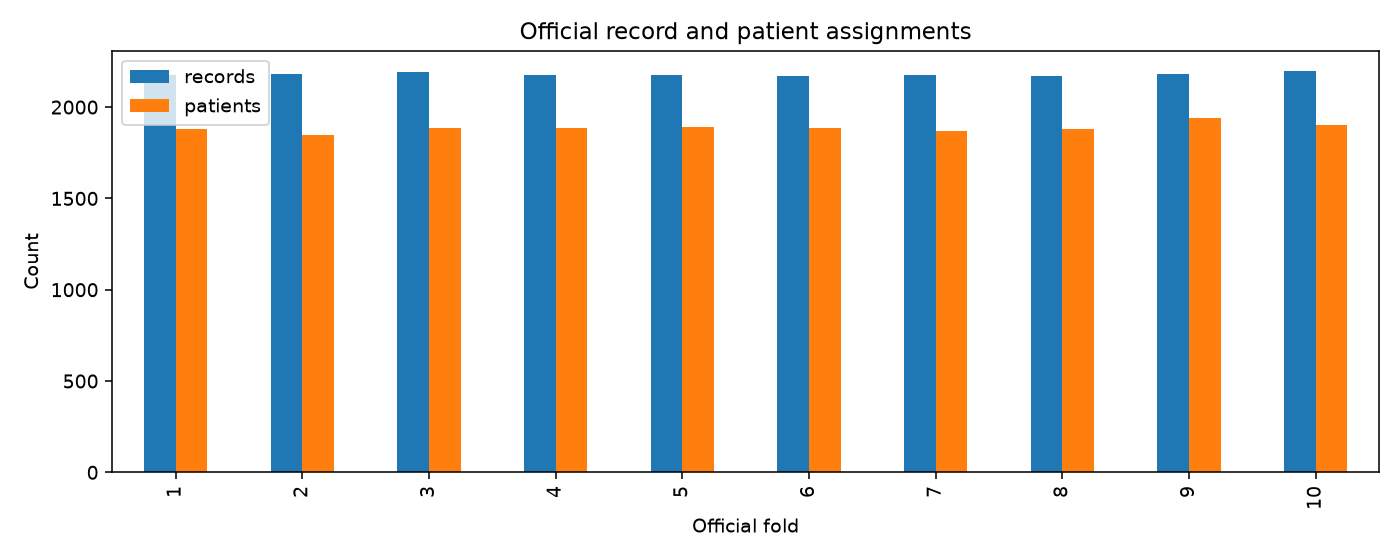

The chart shows metadata counts in the official folds.

No patient occurs in more than one fold; fold 10 is reserved and no test scores are used here.


## Preprocessing

P0 uses raw history; P1 uses causal 0.5–40 Hz SOS Butterworth filtering on observed history only (prototype N=4; bandpass order 8). Both use identical raw-training-history z-scores and predict the same original-mV future. Filtering may distort ST segments, QRS shape, phase, and initial samples; it is a hypothesis. History-only distortion/PSD figures do not establish physiological accuracy.

Measured validation filter effects:

| A | B | split | contrast | percentage_B_minus_A | difference_B_minus_A_mV | ci95_low | ci95_high | patients | bootstrap_samples | conclusion |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| cnn_lstm_P0_F0_lr0.0005_h64_e60 | cnn_lstm_P1_F0_lr0.0005_h64_e60 | val | P0 versus P1 | 0.044678 | 5.07368e-05 | -0.00014501 | 0.000227234 | 1942 | 1000 | inconclusive |
| lstm_P0_F0_lr0.0005_h64_e60 | lstm_P1_F0_lr0.0005_h64_e60 | val | P0 versus P1 | 0.358096 | 0.000406187 | 0.000258577 | 0.000544774 | 1942 | 1000 | did not help |

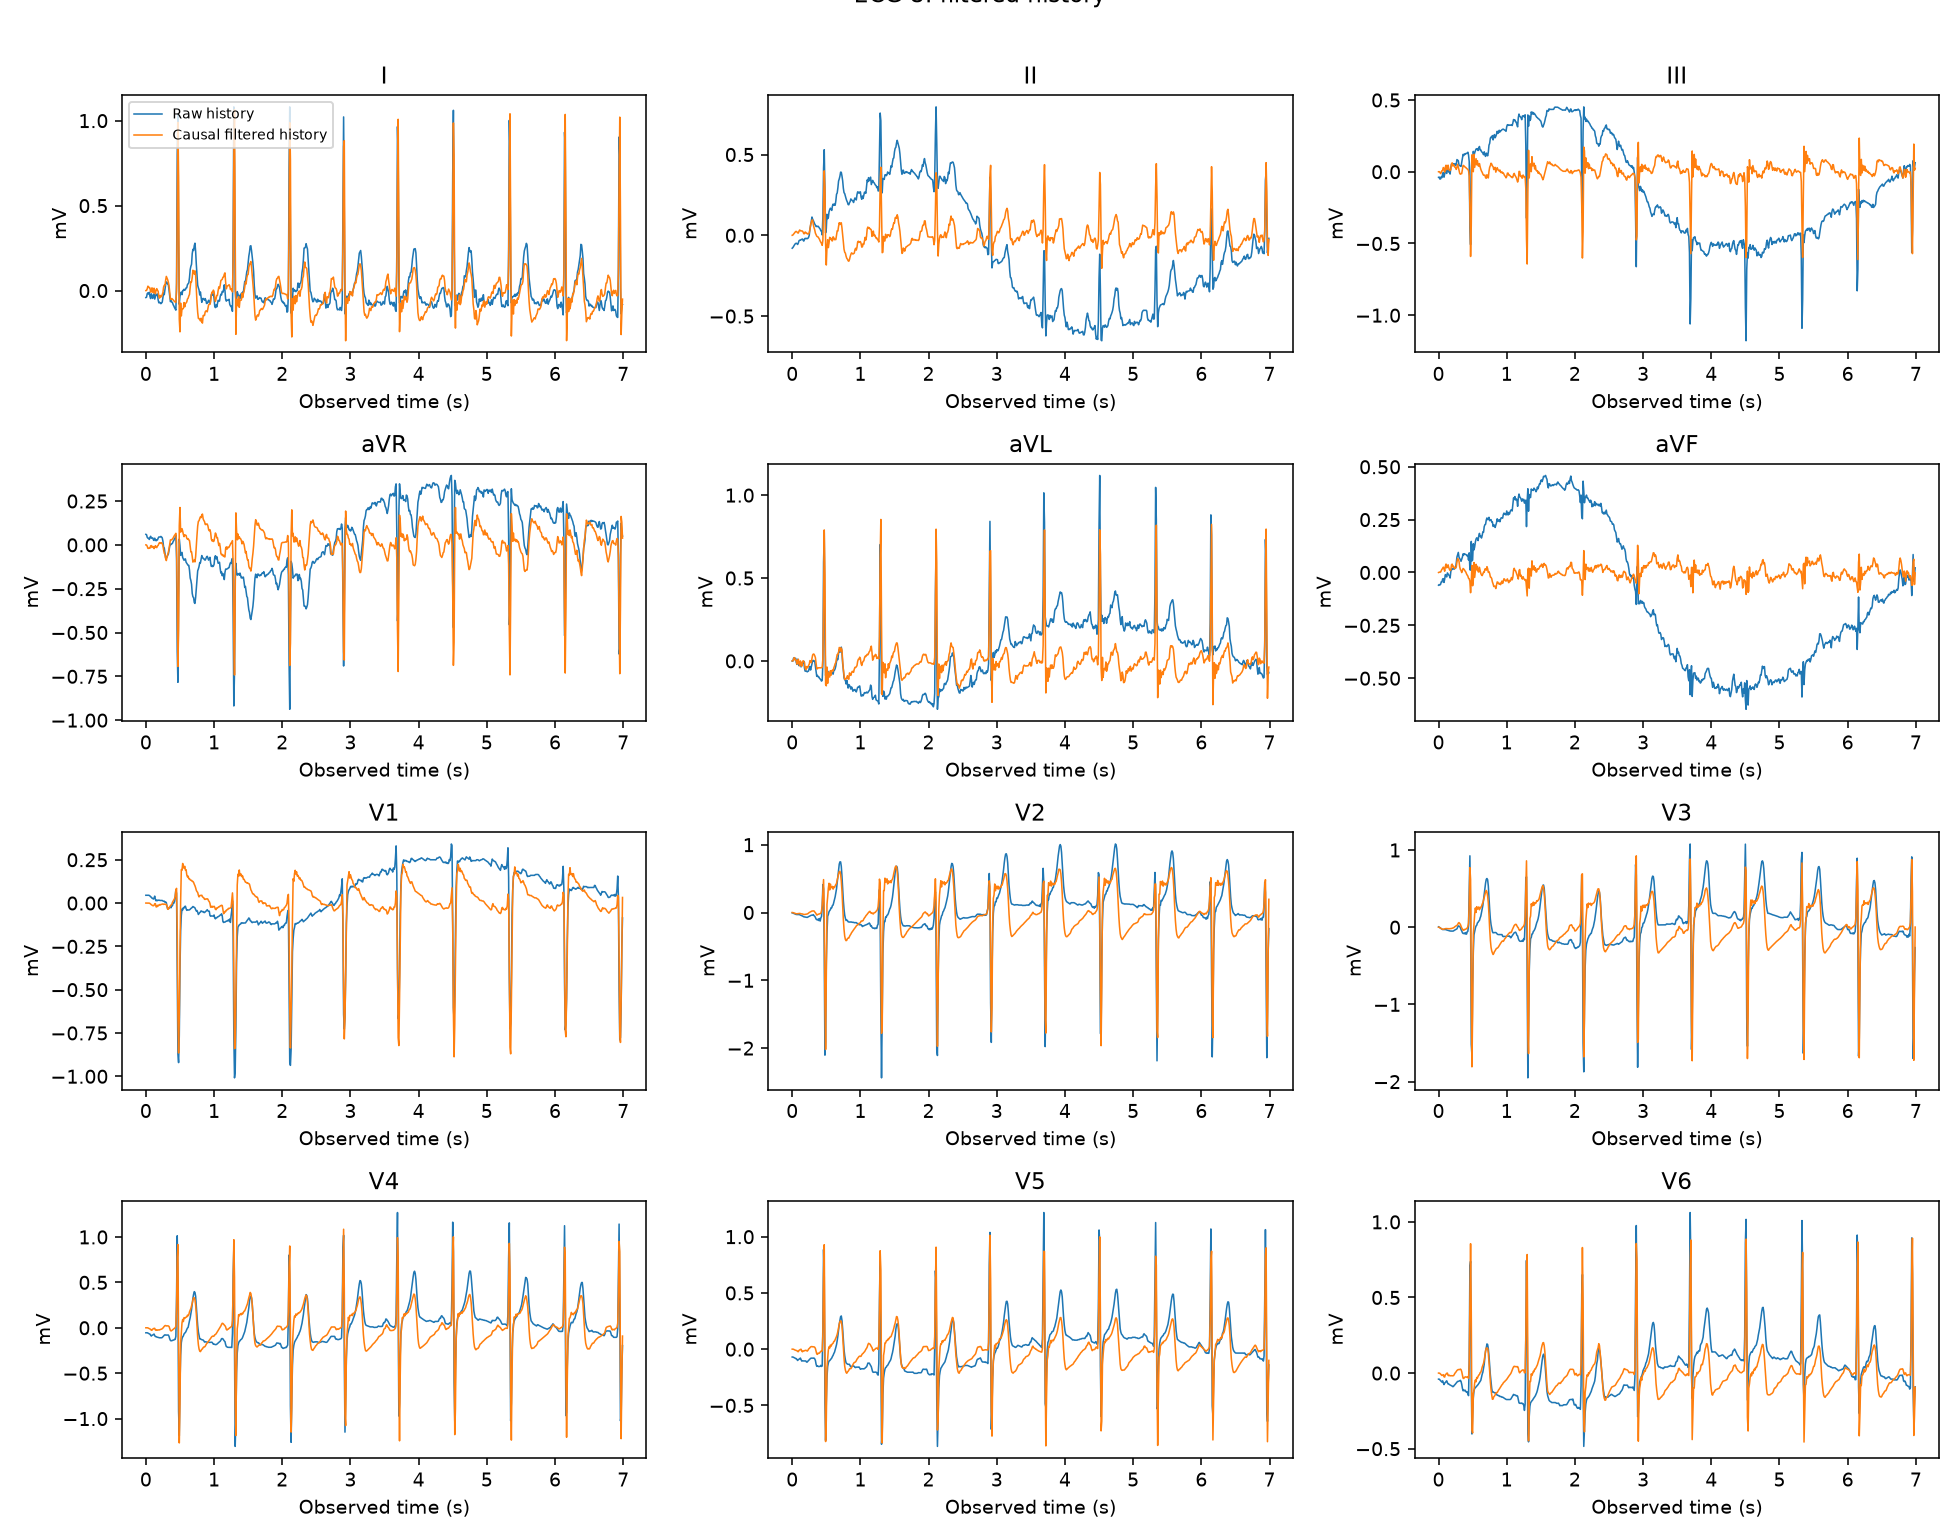

This figure shows all twelve leads for the lowest-ID validation recording (filtered_history).

Filtering changes observed voltages and phase; these plots alone do not establish better forecasts or clinical morphology preservation.


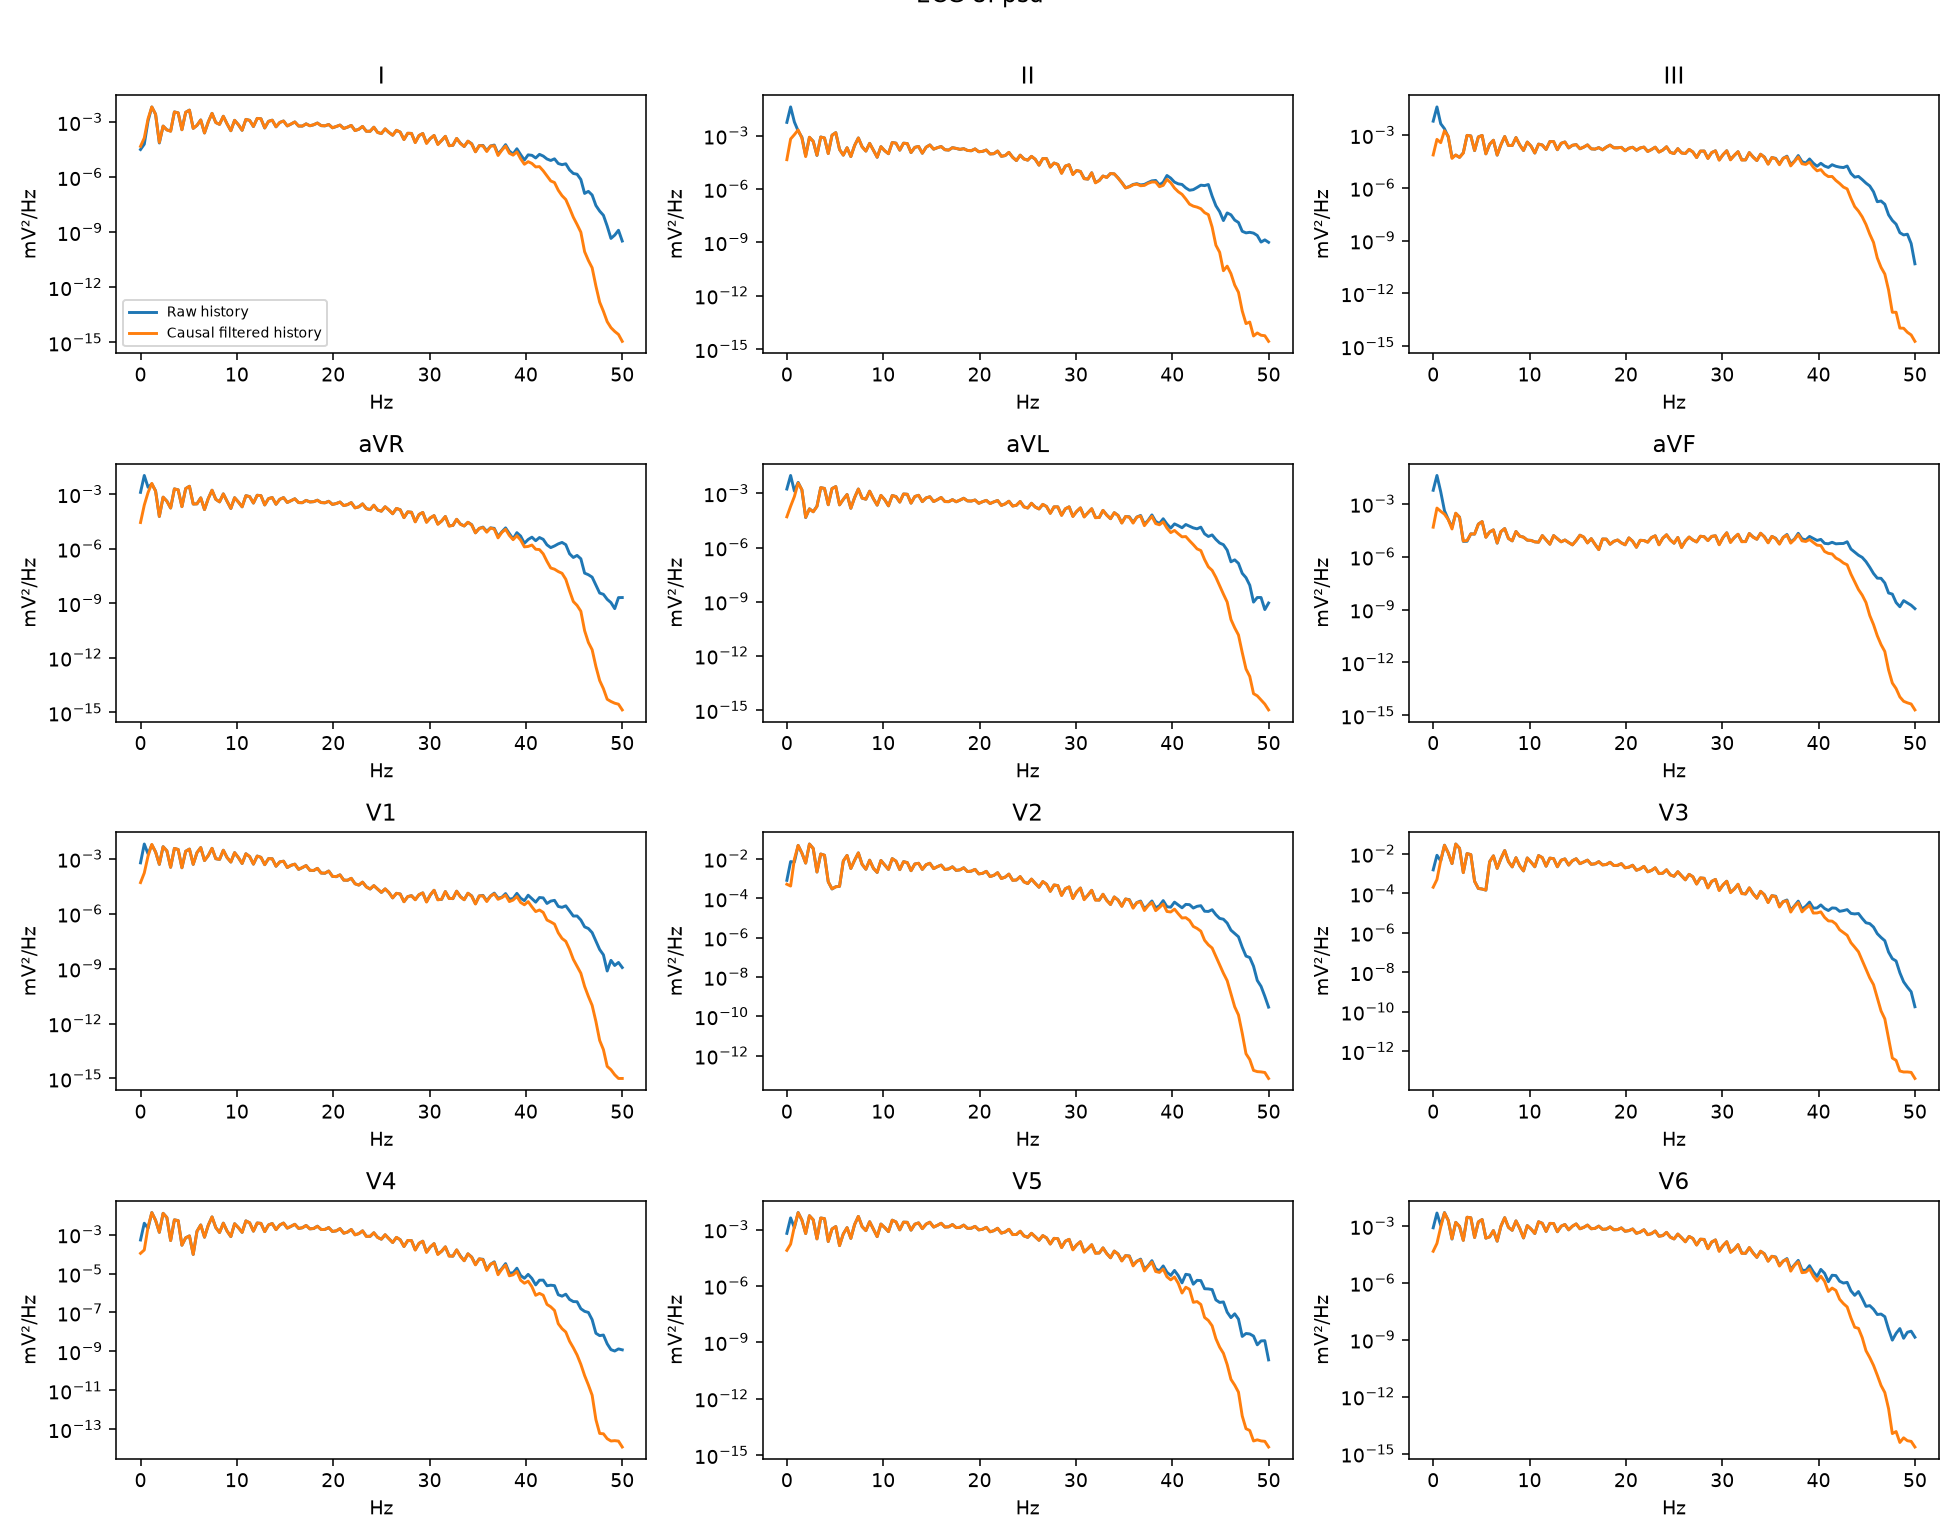

This figure shows all twelve leads for the lowest-ID validation recording (psd).

Filtering changes observed voltages and phase; these plots alone do not establish better forecasts or clinical morphology preservation.


## LSTM

Independent `LSTMForecaster`: optional early static embedding → stacked LSTM → final hidden state → MLP → all future samples. Exact active parameter counts and model settings are in each run.json; see docs/EQUATIONS.md.

| model | filter | features | static_values | hidden | layers | active_parameters | output |
| --- | --- | --- | --- | --- | --- | --- | --- |
| lstm | P0 | permutation | 6 | 64 | 1 | 496896 | [B,300,12] |
| lstm | P0 | mrmr | 6 | 64 | 1 | 496896 | [B,300,12] |
| lstm | P0 | F0 | 0 | 64 | 1 | 492688 | [B,300,12] |
| lstm | P0 | expanded | 16 | 64 | 1 | 497056 | [B,300,12] |
| lstm | P1 | F0 | 0 | 64 | 1 | 492688 | [B,300,12] |
| lstm | P0 | F1 | 4 | 64 | 1 | 496864 | [B,300,12] |

## CNN-LSTM

Independent `CNNLSTMForecaster`: optional static channels → Conv1d(7,32) → ReLU → Conv1d(5,64) → ReLU → AvgPool(2) → LSTM → MLP. The primary 700-step history becomes 350 recurrent steps. No attention or contrastive projector is active.

| model | filter | features | static_values | hidden | layers | active_parameters | output |
| --- | --- | --- | --- | --- | --- | --- | --- |
| cnn_lstm | P0 | F0 | 0 | 64 | 1 | 519024 | [B,300,12] |
| cnn_lstm | P0 | permutation | 6 | 64 | 1 | 522720 | [B,300,12] |
| cnn_lstm | P1 | F0 | 0 | 64 | 1 | 519024 | [B,300,12] |
| cnn_lstm | P0 | F1 | 4 | 64 | 1 | 522688 | [B,300,12] |
| cnn_lstm | P0 | mrmr | 6 | 64 | 1 | 522720 | [B,300,12] |
| cnn_lstm | P0 | expanded | 16 | 64 | 1 | 522880 | [B,300,12] |

## Training

AdamW, normalized MSE, fixed learning rates, gradient clipping, seed 42; validation patient-macro MAE selects checkpoints. No early stopping truncates the budget.

| name | state | epochs_completed | best_epoch | runtime_seconds |
| --- | --- | --- | --- | --- |
| cnn_lstm_P0_F0_lr0.0001_h64_e60 | measured | 60 | 54 | 452.089 |
| cnn_lstm_P0_F0_lr0.0005_h64_e60 | measured | 60 | 16 | 557.055 |
| cnn_lstm_P0_F0_lr0.001_h64_e60 | measured | 60 | 8 | 449.844 |
| cnn_lstm_P0_F1_lr0.0005_h64_e60 | measured | 60 | 26 | 621.149 |
| cnn_lstm_P0_expanded_lr0.001_h64_e60 | measured | 60 | 8 | 649.191 |
| cnn_lstm_P0_mrmr_lr0.001_h64_e60 | measured | 60 | 5 | 649.216 |
| cnn_lstm_P0_permutation_lr0.001_h64_e60 | measured | 60 | 5 | 608.016 |
| cnn_lstm_P1_F0_lr0.0005_h64_e60 | measured | 60 | 9 | 534.424 |
| lstm_P0_F0_lr0.0001_h64_e60 | measured | 60 | 55 | 283.826 |
| lstm_P0_F0_lr0.0005_h64_e60 | measured | 60 | 12 | 276.083 |
| lstm_P0_F0_lr0.001_h64_e60 | measured | 60 | 5 | 264.492 |
| lstm_P0_F1_lr0.0005_h64_e60 | measured | 60 | 14 | 299.633 |
| lstm_P0_expanded_lr0.0005_h64_e60 | measured | 60 | 9 | 282.594 |
| lstm_P0_mrmr_lr0.0005_h64_e60 | measured | 60 | 9 | 278.932 |
| lstm_P0_permutation_lr0.0005_h64_e60 | measured | 60 | 9 | 278.865 |
| lstm_P1_F0_lr0.0005_h64_e60 | measured | 60 | 6 | 283.269 |
| persistence | measured | 0 | pending | pending |
| repeat_window | measured | 0 | pending | pending |

Recorded environments: `[{'python': '3.13.5', 'torch': '2.15.0', 'device': 'cpu', 'gpu': None}, {'python': '3.13.5', 'torch': '2.15.0', 'device': 'cpu', 'gpu': None}, {'python': '3.13.5', 'torch': '2.15.0', 'device': 'cpu', 'gpu': None}, {'python': '3.13.5', 'torch': '2.15.0', 'device': 'cpu', 'gpu': None}, {'python': '3.13.5', 'torch': '2.15.0', 'device': 'cpu', 'gpu': None}, {'python': '3.13.5', 'torch': '2.15.0', 'device': 'cpu', 'gpu': None}, {'python': '3.13.5', 'torch': '2.15.0', 'device': 'cpu', 'gpu': None}, {'python': '3.13.5', 'torch': '2.15.0', 'device': 'cpu', 'gpu': None}, {'python': '3.13.5', 'torch': '2.15.0', 'device': 'cpu', 'gpu': None}, {'python': '3.13.5', 'torch': '2.15.0', 'device': 'cpu', 'gpu': None}, {'python': '3.13.5', 'torch': '2.15.0', 'device': 'cpu', 'gpu': None}, {'python': '3.13.5', 'torch': '2.15.0', 'device': 'cpu', 'gpu': None}, {'python': '3.13.5', 'torch': '2.15.0', 'device': 'cpu', 'gpu': None}, {'python': '3.13.5', 'torch': '2.15.0', 'device': 'cpu', 'gpu': None}, {'python': '3.13.5', 'torch': '2.15.0', 'device': 'cpu', 'gpu': None}, {'python': '3.13.5', 'torch': '2.15.0', 'device': 'cpu', 'gpu': None}]`. Full 120-epoch Colab runs remain pending unless their completed artifacts are present.

60/120 checkpoint evidence:

Pending: no completed comparable research measurements.

## RMSE/MAE

MAE = mean(|prediction − truth|), in mV; RMSE = sqrt(mean((prediction − truth)²)), in mV; MSE is mV². RMSE applies to both regression architectures and is not an LSTM gate. Patient-macro MAE averages records within each patient, then weights patients equally.

| name | split | mae_mV | rmse_mV | patient_macro_mae_mV | mse_mV2 | r2 | pearson_mean |
| --- | --- | --- | --- | --- | --- | --- | --- |
| cnn_lstm_P0_F0_lr0.0001_h64_e60 | val | 0.114167 | 0.236132 | 0.113611 | 0.0557581 | 0.00318548 | 0.0662902 |
| cnn_lstm_P0_F0_lr0.0005_h64_e60 | val | 0.11414 | 0.236119 | 0.113561 | 0.0557519 | 0.00329557 | 0.0736856 |
| cnn_lstm_P0_F0_lr0.001_h64_e60 | val | 0.114026 | 0.236076 | 0.113446 | 0.0557321 | 0.00365096 | 0.0738621 |
| cnn_lstm_P0_F1_lr0.0005_h64_e60 | val | 0.114275 | 0.236374 | 0.113714 | 0.0558725 | 0.00114082 | 0.0759836 |
| cnn_lstm_P0_expanded_lr0.001_h64_e60 | val | 0.114056 | 0.235976 | 0.113483 | 0.0556846 | 0.00449948 | 0.0733333 |
| cnn_lstm_P0_mrmr_lr0.001_h64_e60 | val | 0.114029 | 0.236102 | 0.113485 | 0.0557439 | 0.0034388 | 0.0609083 |
| cnn_lstm_P0_permutation_lr0.001_h64_e60 | val | 0.114061 | 0.236118 | 0.113519 | 0.0557517 | 0.0032996 | 0.0567676 |
| cnn_lstm_P1_F0_lr0.0005_h64_e60 | val | 0.114149 | 0.236074 | 0.113612 | 0.0557309 | 0.00367213 | 0.0468705 |
| lstm_P0_F0_lr0.0001_h64_e60 | val | 0.114031 | 0.235946 | 0.113468 | 0.0556703 | 0.00475482 | 0.0759191 |
| lstm_P0_F0_lr0.0005_h64_e60 | val | 0.114002 | 0.235878 | 0.113429 | 0.0556384 | 0.00532523 | 0.0806669 |
| lstm_P0_F0_lr0.001_h64_e60 | val | 0.114003 | 0.23591 | 0.113447 | 0.0556533 | 0.00505874 | 0.0762107 |
| lstm_P0_F1_lr0.0005_h64_e60 | val | 0.114014 | 0.235896 | 0.113435 | 0.0556467 | 0.0051763 | 0.0825572 |
| lstm_P0_expanded_lr0.0005_h64_e60 | val | 0.114067 | 0.236013 | 0.113517 | 0.0557022 | 0.00418536 | 0.0692256 |
| lstm_P0_mrmr_lr0.0005_h64_e60 | val | 0.114055 | 0.236057 | 0.113497 | 0.0557227 | 0.00381802 | 0.0679639 |
| lstm_P0_permutation_lr0.0005_h64_e60 | val | 0.114001 | 0.236022 | 0.113449 | 0.0557066 | 0.00410655 | 0.0702252 |
| lstm_P1_F0_lr0.0005_h64_e60 | val | 0.114367 | 0.236264 | 0.113836 | 0.0558209 | 0.00206371 | 0.0343163 |
| persistence | val | 0.160413 | 0.314331 | 0.160367 | 0.0988042 | -0.76637 | 0.0299717 |
| repeat_window | val | 0.170941 | 0.326306 | 0.170786 | 0.106476 | -0.903519 | -0.0160786 |

## Twelve-lead prediction

Saved figures show each lead separately with observed history, original future truth, forecast, physical axes, and the forecast boundary. The pre-specified example is selected by metadata ID before errors; the median-error example is labelled. No fabricated peak markers or unvalidated P/Q/R/S/T delineation are used.

| lead | mae_mV | rmse_mV | pearson | name | split |
| --- | --- | --- | --- | --- | --- |
| I | 0.08486 | 0.152835 | 0.04429 | cnn_lstm_P0_F0_lr0.0001_h64_e60 | val |
| II | 0.0965986 | 0.167539 | 0.0752482 | cnn_lstm_P0_F0_lr0.0001_h64_e60 | val |
| III | 0.0870131 | 0.166458 | 0.0724611 | cnn_lstm_P0_F0_lr0.0001_h64_e60 | val |
| aVR | 0.0800372 | 0.137021 | 0.0591839 | cnn_lstm_P0_F0_lr0.0001_h64_e60 | val |
| aVL | 0.0718439 | 0.136102 | 0.0530171 | cnn_lstm_P0_F0_lr0.0001_h64_e60 | val |
| aVF | 0.0802974 | 0.148346 | 0.0812636 | cnn_lstm_P0_F0_lr0.0001_h64_e60 | val |
| V1 | 0.108083 | 0.221314 | 0.049336 | cnn_lstm_P0_F0_lr0.0001_h64_e60 | val |
| V2 | 0.169581 | 0.342258 | 0.0829863 | cnn_lstm_P0_F0_lr0.0001_h64_e60 | val |
| V3 | 0.173069 | 0.327743 | 0.0796502 | cnn_lstm_P0_F0_lr0.0001_h64_e60 | val |
| V4 | 0.159898 | 0.3593 | 0.0289687 | cnn_lstm_P0_F0_lr0.0001_h64_e60 | val |
| V5 | 0.137573 | 0.261046 | 0.0294568 | cnn_lstm_P0_F0_lr0.0001_h64_e60 | val |
| V6 | 0.121149 | 0.244701 | 0.13962 | cnn_lstm_P0_F0_lr0.0001_h64_e60 | val |
| I | 0.0852305 | 0.152993 | 0.0492235 | cnn_lstm_P0_F0_lr0.0005_h64_e60 | val |
| II | 0.0962756 | 0.167159 | 0.0972676 | cnn_lstm_P0_F0_lr0.0005_h64_e60 | val |
| III | 0.0870323 | 0.166251 | 0.0884445 | cnn_lstm_P0_F0_lr0.0005_h64_e60 | val |
| aVR | 0.0800357 | 0.136982 | 0.0696148 | cnn_lstm_P0_F0_lr0.0005_h64_e60 | val |
| aVL | 0.0721438 | 0.136158 | 0.0616375 | cnn_lstm_P0_F0_lr0.0005_h64_e60 | val |
| aVF | 0.0800587 | 0.14803 | 0.101306 | cnn_lstm_P0_F0_lr0.0005_h64_e60 | val |
| V1 | 0.108694 | 0.221227 | 0.0571941 | cnn_lstm_P0_F0_lr0.0005_h64_e60 | val |
| V2 | 0.169619 | 0.341957 | 0.092641 | cnn_lstm_P0_F0_lr0.0005_h64_e60 | val |
| V3 | 0.172971 | 0.327402 | 0.0913471 | cnn_lstm_P0_F0_lr0.0005_h64_e60 | val |
| V4 | 0.159608 | 0.359649 | 0.023255 | cnn_lstm_P0_F0_lr0.0005_h64_e60 | val |
| V5 | 0.137178 | 0.261148 | 0.0324924 | cnn_lstm_P0_F0_lr0.0005_h64_e60 | val |
| V6 | 0.120839 | 0.245368 | 0.119803 | cnn_lstm_P0_F0_lr0.0005_h64_e60 | val |

## Evidence-based comparison

| A | B | split | contrast | percentage_B_minus_A | difference_B_minus_A_mV | ci95_low | ci95_high | patients | bootstrap_samples | conclusion |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| cnn_lstm_P0_F0_lr0.0001_h64_e60 | cnn_lstm_P0_F0_lr0.0005_h64_e60 | val | learning-rate comparison | -0.0444013 | -5.0445e-05 | -0.000136645 | 5.46881e-05 | 1942 | 1000 | inconclusive |
| cnn_lstm_P0_F0_lr0.0001_h64_e60 | cnn_lstm_P0_F0_lr0.001_h64_e60 | val | learning-rate comparison | -0.145304 | -0.000165082 | -0.000250456 | -8.16534e-05 | 1942 | 1000 | helped |
| cnn_lstm_P0_F0_lr0.0001_h64_e60 | lstm_P0_F0_lr0.0001_h64_e60 | val | matched architecture comparison | -0.126618 | -0.000143852 | -0.000269193 | -3.04959e-05 | 1942 | 1000 | helped |
| persistence | cnn_lstm_P0_F0_lr0.0001_h64_e60 | val | neural pipeline versus raw-history baseline | -29.1552 | -0.0467553 | -0.0516834 | -0.0414592 | 1942 | 1000 | helped |
| repeat_window | cnn_lstm_P0_F0_lr0.0001_h64_e60 | val | neural pipeline versus raw-history baseline | -33.4773 | -0.0571746 | -0.059106 | -0.0552202 | 1942 | 1000 | helped |
| cnn_lstm_P0_F0_lr0.0005_h64_e60 | cnn_lstm_P0_F0_lr0.001_h64_e60 | val | learning-rate comparison | -0.100947 | -0.000114637 | -0.000217962 | -2.27497e-05 | 1942 | 1000 | helped |
| cnn_lstm_P0_F0_lr0.0005_h64_e60 | cnn_lstm_P0_F1_lr0.0005_h64_e60 | val | static-feature ablation | 0.135091 | 0.00015341 | -1.47709e-05 | 0.000384975 | 1942 | 1000 | inconclusive |
| cnn_lstm_P0_F0_lr0.0005_h64_e60 | cnn_lstm_P1_F0_lr0.0005_h64_e60 | val | P0 versus P1 | 0.044678 | 5.07368e-05 | -0.00014501 | 0.000227234 | 1942 | 1000 | inconclusive |
| cnn_lstm_P0_F0_lr0.0005_h64_e60 | lstm_P0_F0_lr0.0005_h64_e60 | val | matched architecture comparison | -0.1159 | -0.000131618 | -0.000278544 | -6.40248e-06 | 1942 | 1000 | helped |
| persistence | cnn_lstm_P0_F0_lr0.0005_h64_e60 | val | neural pipeline versus raw-history baseline | -29.1867 | -0.0468058 | -0.0517578 | -0.0414872 | 1942 | 1000 | helped |
| repeat_window | cnn_lstm_P0_F0_lr0.0005_h64_e60 | val | neural pipeline versus raw-history baseline | -33.5068 | -0.057225 | -0.0591409 | -0.0552447 | 1942 | 1000 | helped |
| cnn_lstm_P0_F0_lr0.001_h64_e60 | cnn_lstm_P0_expanded_lr0.001_h64_e60 | val | static-feature ablation | 0.032424 | 3.67838e-05 | -6.18776e-05 | 0.000126722 | 1942 | 1000 | inconclusive |
| cnn_lstm_P0_F0_lr0.001_h64_e60 | cnn_lstm_P0_mrmr_lr0.001_h64_e60 | val | static-feature ablation | 0.0341674 | 3.87616e-05 | -8.75224e-05 | 0.000156697 | 1942 | 1000 | inconclusive |
| cnn_lstm_P0_F0_lr0.001_h64_e60 | cnn_lstm_P0_permutation_lr0.001_h64_e60 | val | static-feature ablation | 0.0641493 | 7.27751e-05 | -5.19701e-05 | 0.000186934 | 1942 | 1000 | inconclusive |
| cnn_lstm_P0_F0_lr0.001_h64_e60 | lstm_P0_F0_lr0.001_h64_e60 | val | matched architecture comparison | 0.000517147 | 5.86685e-07 | -0.000123609 | 0.000101632 | 1942 | 1000 | inconclusive |
| persistence | cnn_lstm_P0_F0_lr0.001_h64_e60 | val | neural pipeline versus raw-history baseline | -29.2582 | -0.0469204 | -0.051954 | -0.0416146 | 1942 | 1000 | helped |
| repeat_window | cnn_lstm_P0_F0_lr0.001_h64_e60 | val | neural pipeline versus raw-history baseline | -33.574 | -0.0573397 | -0.0592659 | -0.055354 | 1942 | 1000 | helped |
| cnn_lstm_P0_F1_lr0.0005_h64_e60 | lstm_P0_F1_lr0.0005_h64_e60 | val | matched architecture comparison | -0.246093 | -0.000279843 | -0.000602592 | -3.66887e-05 | 1942 | 1000 | helped |
| persistence | cnn_lstm_P0_F1_lr0.0005_h64_e60 | val | neural pipeline versus raw-history baseline | -29.091 | -0.0466524 | -0.0515358 | -0.0413558 | 1942 | 1000 | helped |
| repeat_window | cnn_lstm_P0_F1_lr0.0005_h64_e60 | val | neural pipeline versus raw-history baseline | -33.417 | -0.0570716 | -0.0590507 | -0.0549898 | 1942 | 1000 | helped |
| cnn_lstm_P0_expanded_lr0.001_h64_e60 | cnn_lstm_P0_mrmr_lr0.001_h64_e60 | val | static-feature ablation | 0.00174282 | 1.97781e-06 | -9.8403e-05 | 0.000103549 | 1942 | 1000 | inconclusive |
| cnn_lstm_P0_expanded_lr0.001_h64_e60 | cnn_lstm_P0_permutation_lr0.001_h64_e60 | val | static-feature ablation | 0.031715 | 3.59912e-05 | -5.78524e-05 | 0.000137409 | 1942 | 1000 | inconclusive |
| persistence | cnn_lstm_P0_expanded_lr0.001_h64_e60 | val | neural pipeline versus raw-history baseline | -29.2352 | -0.0468836 | -0.0518729 | -0.0415766 | 1942 | 1000 | helped |
| repeat_window | cnn_lstm_P0_expanded_lr0.001_h64_e60 | val | neural pipeline versus raw-history baseline | -33.5524 | -0.0573029 | -0.059205 | -0.0553261 | 1942 | 1000 | helped |
| cnn_lstm_P0_mrmr_lr0.001_h64_e60 | cnn_lstm_P0_permutation_lr0.001_h64_e60 | val | static-feature ablation | 0.0299717 | 3.40134e-05 | 1.42319e-05 | 5.35138e-05 | 1942 | 1000 | did not help |
| persistence | cnn_lstm_P0_mrmr_lr0.001_h64_e60 | val | neural pipeline versus raw-history baseline | -29.234 | -0.0468817 | -0.051844 | -0.041645 | 1942 | 1000 | helped |
| repeat_window | cnn_lstm_P0_mrmr_lr0.001_h64_e60 | val | neural pipeline versus raw-history baseline | -33.5513 | -0.0573009 | -0.0592036 | -0.0553462 | 1942 | 1000 | helped |
| persistence | cnn_lstm_P0_permutation_lr0.001_h64_e60 | val | neural pipeline versus raw-history baseline | -29.2128 | -0.0468476 | -0.0518074 | -0.0416131 | 1942 | 1000 | helped |
| repeat_window | cnn_lstm_P0_permutation_lr0.001_h64_e60 | val | neural pipeline versus raw-history baseline | -33.5314 | -0.0572669 | -0.0591802 | -0.0553036 | 1942 | 1000 | helped |
| cnn_lstm_P1_F0_lr0.0005_h64_e60 | lstm_P1_F0_lr0.0005_h64_e60 | val | matched architecture comparison | 0.197015 | 0.000223832 | 0.000166692 | 0.000277235 | 1942 | 1000 | did not help |
| persistence | cnn_lstm_P1_F0_lr0.0005_h64_e60 | val | neural pipeline versus raw-history baseline | -29.1551 | -0.046755 | -0.0517388 | -0.0414751 | 1942 | 1000 | helped |
| repeat_window | cnn_lstm_P1_F0_lr0.0005_h64_e60 | val | neural pipeline versus raw-history baseline | -33.4771 | -0.0571743 | -0.0590723 | -0.055219 | 1942 | 1000 | helped |
| lstm_P0_F0_lr0.0001_h64_e60 | lstm_P0_F0_lr0.0005_h64_e60 | val | learning-rate comparison | -0.0336752 | -3.82105e-05 | -7.77837e-05 | 6.38234e-06 | 1942 | 1000 | inconclusive |
| lstm_P0_F0_lr0.0001_h64_e60 | lstm_P0_F0_lr0.001_h64_e60 | val | learning-rate comparison | -0.0181927 | -2.06429e-05 | -7.47428e-05 | 2.10843e-05 | 1942 | 1000 | inconclusive |
| persistence | lstm_P0_F0_lr0.0001_h64_e60 | val | neural pipeline versus raw-history baseline | -29.2449 | -0.0468992 | -0.0518566 | -0.0416212 | 1942 | 1000 | helped |
| repeat_window | lstm_P0_F0_lr0.0001_h64_e60 | val | neural pipeline versus raw-history baseline | -33.5615 | -0.0573184 | -0.0592518 | -0.0553504 | 1942 | 1000 | helped |
| lstm_P0_F0_lr0.0005_h64_e60 | lstm_P0_F0_lr0.001_h64_e60 | val | learning-rate comparison | 0.0154877 | 1.75676e-05 | -5.5267e-05 | 7.1745e-05 | 1942 | 1000 | inconclusive |
| lstm_P0_F0_lr0.0005_h64_e60 | lstm_P0_F1_lr0.0005_h64_e60 | val | static-feature ablation | 0.00457105 | 5.18492e-06 | -7.14909e-05 | 8.16098e-05 | 1942 | 1000 | inconclusive |
| lstm_P0_F0_lr0.0005_h64_e60 | lstm_P0_expanded_lr0.0005_h64_e60 | val | static-feature ablation | 0.0770087 | 8.73505e-05 | -1.10699e-05 | 0.000177054 | 1942 | 1000 | inconclusive |
| lstm_P0_F0_lr0.0005_h64_e60 | lstm_P0_mrmr_lr0.0005_h64_e60 | val | static-feature ablation | 0.0594965 | 6.74866e-05 | -2.03193e-05 | 0.000148248 | 1942 | 1000 | inconclusive |
| lstm_P0_F0_lr0.0005_h64_e60 | lstm_P0_permutation_lr0.0005_h64_e60 | val | static-feature ablation | 0.0169025 | 1.91724e-05 | -6.57664e-05 | 9.77242e-05 | 1942 | 1000 | inconclusive |
| lstm_P0_F0_lr0.0005_h64_e60 | lstm_P1_F0_lr0.0005_h64_e60 | val | P0 versus P1 | 0.358096 | 0.000406187 | 0.000258577 | 0.000544774 | 1942 | 1000 | did not help |
| persistence | lstm_P0_F0_lr0.0005_h64_e60 | val | neural pipeline versus raw-history baseline | -29.2688 | -0.0469374 | -0.0519038 | -0.0416454 | 1942 | 1000 | helped |
| repeat_window | lstm_P0_F0_lr0.0005_h64_e60 | val | neural pipeline versus raw-history baseline | -33.5839 | -0.0573566 | -0.0592931 | -0.0553881 | 1942 | 1000 | helped |
| persistence | lstm_P0_F0_lr0.001_h64_e60 | val | neural pipeline versus raw-history baseline | -29.2578 | -0.0469198 | -0.0518951 | -0.041643 | 1942 | 1000 | helped |
| repeat_window | lstm_P0_F0_lr0.001_h64_e60 | val | neural pipeline versus raw-history baseline | -33.5736 | -0.0573391 | -0.0592648 | -0.0553768 | 1942 | 1000 | helped |
| lstm_P0_F1_lr0.0005_h64_e60 | lstm_P0_expanded_lr0.0005_h64_e60 | val | static-feature ablation | 0.0724343 | 8.21656e-05 | -1.16173e-05 | 0.000170547 | 1942 | 1000 | inconclusive |
| lstm_P0_F1_lr0.0005_h64_e60 | lstm_P0_mrmr_lr0.0005_h64_e60 | val | static-feature ablation | 0.0549229 | 6.23016e-05 | -2.91447e-05 | 0.000140482 | 1942 | 1000 | inconclusive |
| lstm_P0_F1_lr0.0005_h64_e60 | lstm_P0_permutation_lr0.0005_h64_e60 | val | static-feature ablation | 0.0123308 | 1.39874e-05 | -7.73865e-05 | 9.30643e-05 | 1942 | 1000 | inconclusive |
| persistence | lstm_P0_F1_lr0.0005_h64_e60 | val | neural pipeline versus raw-history baseline | -29.2655 | -0.0469322 | -0.0519367 | -0.0416551 | 1942 | 1000 | helped |
| repeat_window | lstm_P0_F1_lr0.0005_h64_e60 | val | neural pipeline versus raw-history baseline | -33.5809 | -0.0573515 | -0.0592499 | -0.055409 | 1942 | 1000 | helped |
| lstm_P0_expanded_lr0.0005_h64_e60 | lstm_P0_mrmr_lr0.0005_h64_e60 | val | static-feature ablation | -0.0174987 | -1.9864e-05 | -5.34506e-05 | 1.69033e-05 | 1942 | 1000 | inconclusive |
| lstm_P0_expanded_lr0.0005_h64_e60 | lstm_P0_permutation_lr0.0005_h64_e60 | val | static-feature ablation | -0.06006 | -6.81782e-05 | -0.00010303 | -3.204e-05 | 1942 | 1000 | helped |
| persistence | lstm_P0_expanded_lr0.0005_h64_e60 | val | neural pipeline versus raw-history baseline | -29.2143 | -0.04685 | -0.051818 | -0.0416064 | 1942 | 1000 | helped |
| repeat_window | lstm_P0_expanded_lr0.0005_h64_e60 | val | neural pipeline versus raw-history baseline | -33.5328 | -0.0572693 | -0.0591756 | -0.0553378 | 1942 | 1000 | helped |
| lstm_P0_mrmr_lr0.0005_h64_e60 | lstm_P0_permutation_lr0.0005_h64_e60 | val | static-feature ablation | -0.0425687 | -4.83142e-05 | -6.77309e-05 | -3.07302e-05 | 1942 | 1000 | helped |
| persistence | lstm_P0_mrmr_lr0.0005_h64_e60 | val | neural pipeline versus raw-history baseline | -29.2267 | -0.0468699 | -0.0518344 | -0.0416044 | 1942 | 1000 | helped |
| repeat_window | lstm_P0_mrmr_lr0.0005_h64_e60 | val | neural pipeline versus raw-history baseline | -33.5444 | -0.0572892 | -0.059201 | -0.0553592 | 1942 | 1000 | helped |
| persistence | lstm_P0_permutation_lr0.0005_h64_e60 | val | neural pipeline versus raw-history baseline | -29.2568 | -0.0469182 | -0.0518862 | -0.0416508 | 1942 | 1000 | helped |
| repeat_window | lstm_P0_permutation_lr0.0005_h64_e60 | val | neural pipeline versus raw-history baseline | -33.5727 | -0.0573375 | -0.0592565 | -0.055412 | 1942 | 1000 | helped |
| persistence | lstm_P1_F0_lr0.0005_h64_e60 | val | neural pipeline versus raw-history baseline | -29.0155 | -0.0465312 | -0.0514903 | -0.0412381 | 1942 | 1000 | helped |
| repeat_window | lstm_P1_F0_lr0.0005_h64_e60 | val | neural pipeline versus raw-history baseline | -33.3461 | -0.0569505 | -0.0588544 | -0.0550117 | 1942 | 1000 | helped |

Negative B−A favors B. Intervals resample patients and are descriptive after validation selection, using one seed without multiplicity correction. Medium/full cohorts and different horizons are not pooled. Low voltage error does not establish clinical validity; 100-Hz resolution and filter/morphology limitations remain. ARIMA is deferred. Feature-selection execution is pending unless feature_extension.json exists. Synthetic and pilot runs are software checks, not research performance evidence.

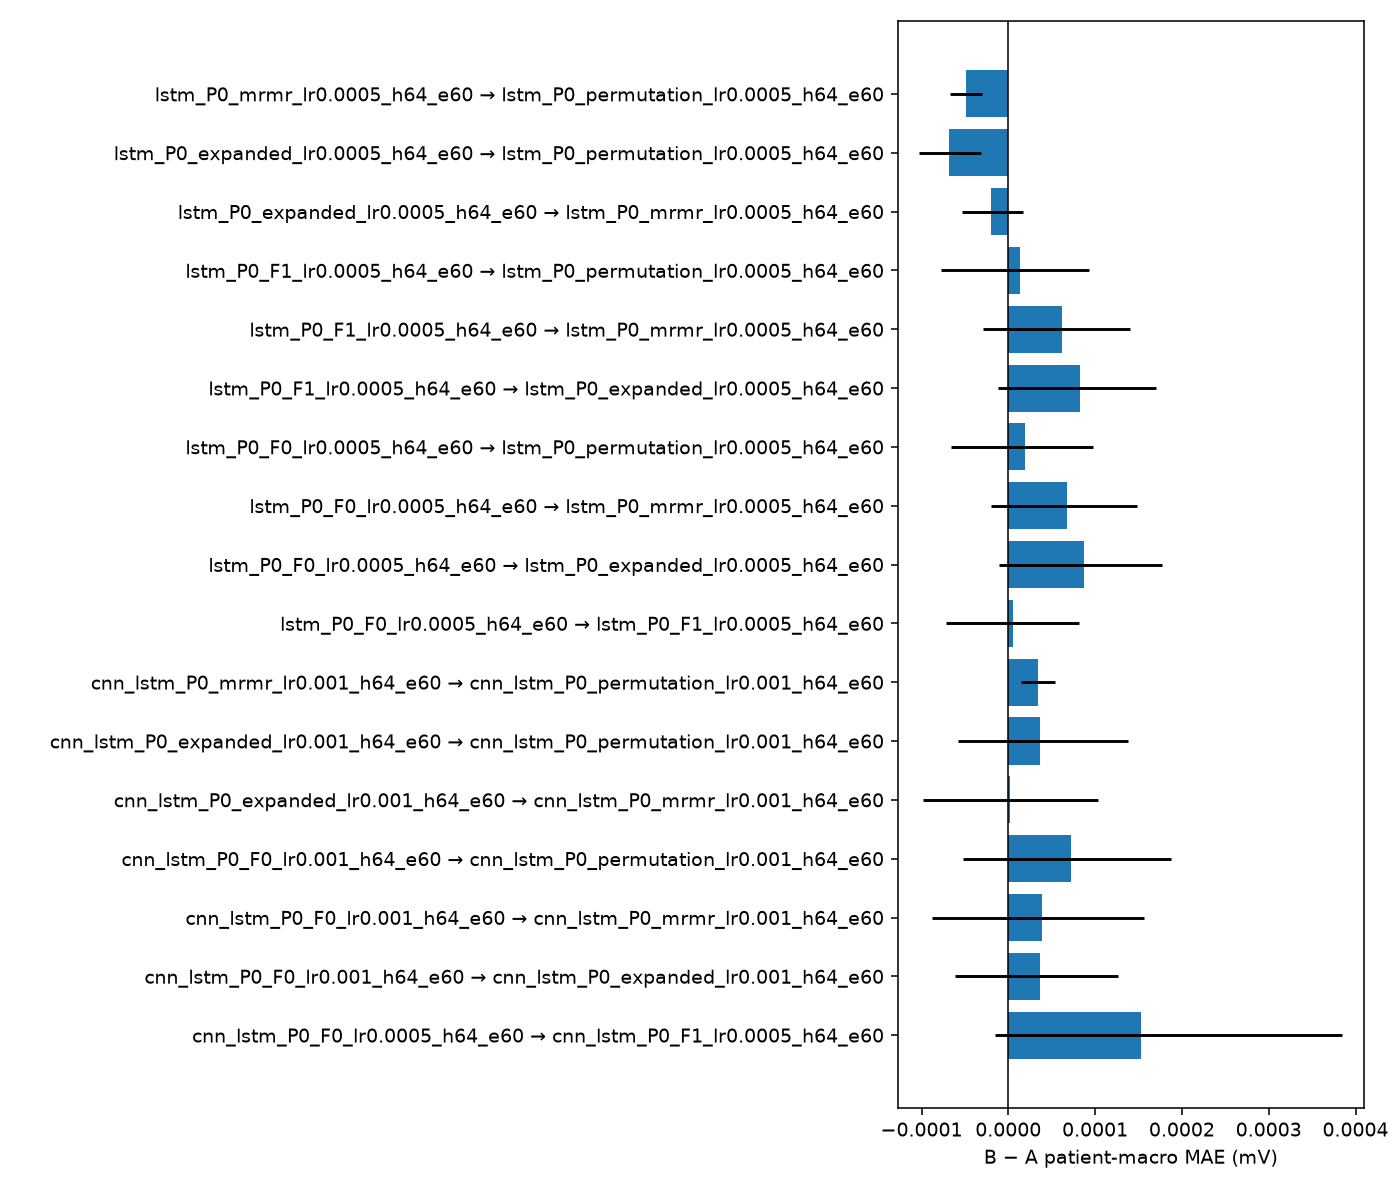

Matched static-feature ablation differences and paired patient-bootstrap intervals are shown.

Negative differences favor B; intervals crossing zero are inconclusive, and single-seed intervals do not capture training variability.


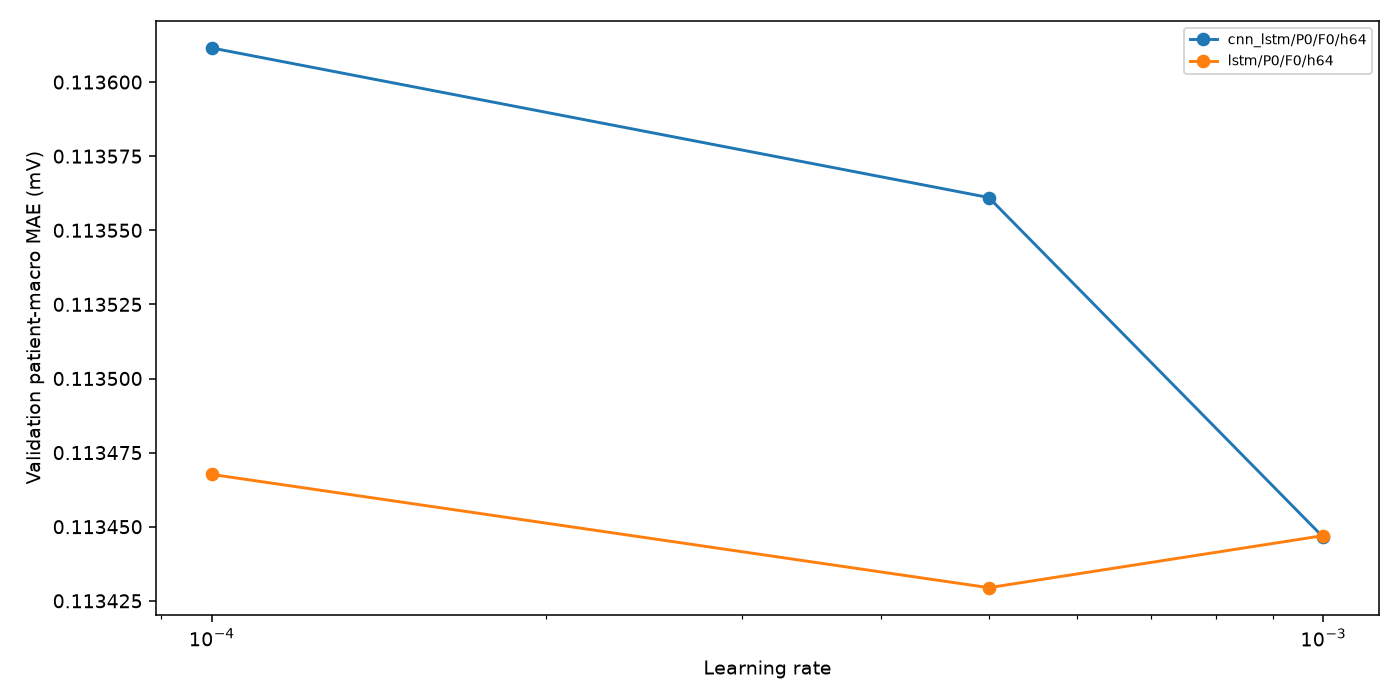

Validation results compare the tested learning rates within fixed recipes.

The selected rate is best among these measured candidates, not a proven global optimum.


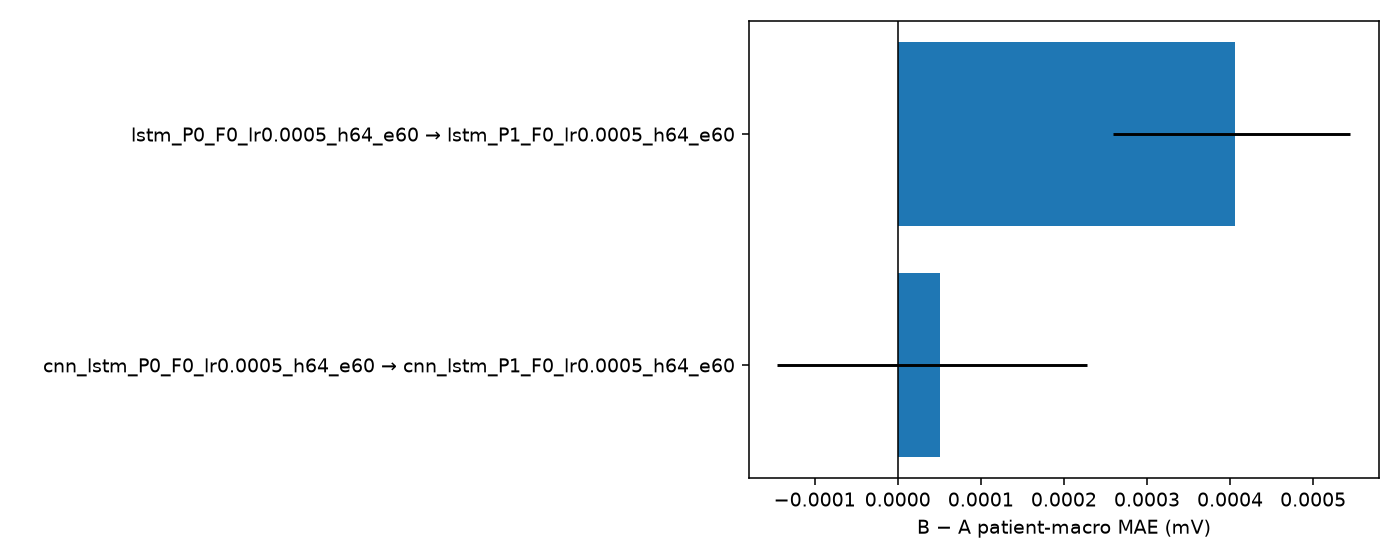

Matched P0 versus P1 differences and paired patient-bootstrap intervals are shown.

Negative differences favor B; intervals crossing zero are inconclusive, and single-seed intervals do not capture training variability.


Saved report: results/primary_7s3s_v5/medium/RESULTS.md
Saved ZIP: results/primary_7s3s_v5/PTBXL_Research_Results.zip


In [36]:
from IPython.display import Markdown, Image, display
from report import generate, bundle, SUMMARY_ORDER
from config import read_json

report_path = generate(cfg)
summary = read_json(report_path.parent / 'summary.json')
if summary['warning']:
    display(Markdown(summary['warning']))
figures = report_path.parent / 'figures'
medium_figures = study_dir(cfg) / 'medium' / 'figures' / 'comparisons'
image_groups = {
    'Patient-safe folds': list(figures.glob('data/fold_counts.png')),
    'Preprocessing': list(figures.glob('data/filtered_history.png')) + list(figures.glob('data/psd.png')),
    'Training': list(figures.glob('*/learning_curves.png'))[:2],
    'Twelve-lead prediction': list(figures.glob('*/*pre_specified_12_leads.png'))[:2] + list(figures.glob('*/*median_error_12_leads.png'))[:2],
    'Evidence-based comparison': list(figures.glob('comparisons/*.png'))[:3] + (
        [p for p in medium_figures.glob('*.png') if any(k in p.name for k in ('learning_rate', 'feature_sets'))]
        if cfg['run_mode'] == 'full' else []
    ),
}
for section in SUMMARY_ORDER:
    display(Markdown('## ' + section + '\n\n' + summary['sections'][section]))
    for path in image_groups.get(section, []):
        display(Image(filename=str(path)))
        caption = path.with_suffix('.md')
        if caption.exists():
            display(Markdown(caption.read_text(encoding='utf-8')))
archive_path = bundle(cfg)
print('Saved report:', report_path)
print('Saved ZIP:', archive_path)